In [15]:
import pyuvdata
import numpy as np
import matplotlib.pyplot as plt

In [7]:
uv = pyuvdata.UVData()
uv.read("/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_peeled.uvfits")

In [9]:
np.sum(uv.flag_array) / np.size(uv.flag_array)

np.float64(0.2755854006890822)

In [10]:
np.shape(uv.flag_array)

(745536, 295, 4)

In [11]:
uv_xx = uv.select(polarizations=[-5], inplace=False)

In [12]:
uv_yy = uv.select(polarizations=[-6], inplace=False)

In [13]:
np.sum(uv_xx.flag_array) / np.size(uv_xx.flag_array)

np.float64(0.27447955542121166)

In [14]:
np.sum(uv_yy.flag_array) / np.size(uv_yy.flag_array)

np.float64(0.27657714308786235)

Text(0, 0.5, 'Number of Flags')

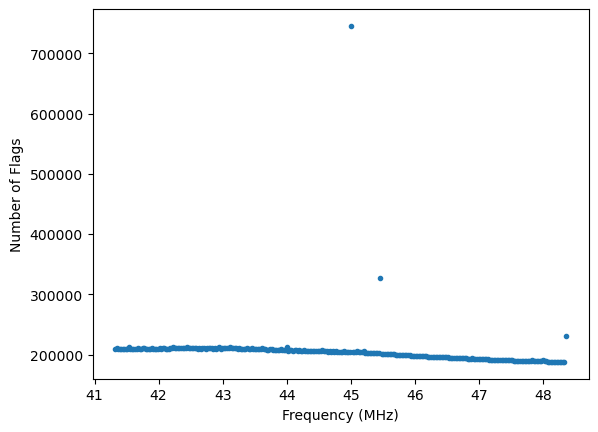

In [19]:
plt.plot(uv_xx.freq_array/1e6, np.sum(uv_xx.flag_array, axis=0), ".")
plt.xlabel("Frequency (MHz)")
plt.ylabel("Number of Flags")

Text(0, 0.5, 'Number of Flags')

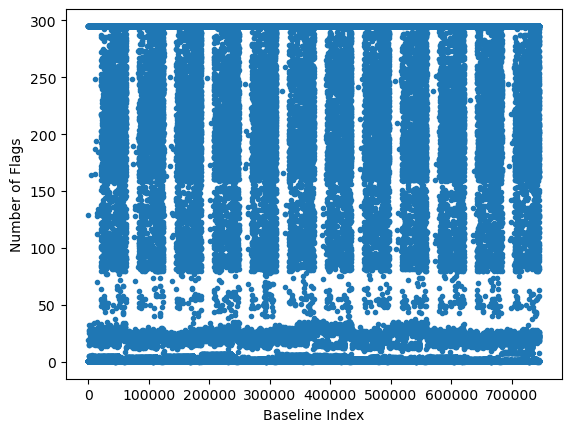

In [23]:
plt.plot(np.sum(uv_xx.flag_array, axis=1), ".")
plt.xlabel("Baseline Index")
plt.ylabel("Number of Flags")

In [24]:
uv_flags_extended = uv.copy()
uv_flags_extended.flag_array[:, :, :] = np.max(uv_flags_extended.flag_array, axis=1)[:, np.newaxis, :]

In [25]:
np.sum(uv_flags_extended.flag_array) / np.size(uv_flags_extended.flag_array)

np.float64(0.9999222036226285)